# INX Future Inc. Employee Performance Analysis

This notebook explores employee data to identify performance patterns, compare performance across departments, and understand the factors associated with employee performance.

The analysis will support data-driven recommendations for improving employee performance.

## 1: Introduction and Data Loading

### 1. Import Libraries

Import the libraries required for data analysis and visualization.

In [1]:
import pandas as pd
import numpy as np 
import matplotlib.pyplot as plt 
import seaborn as sns 
from pathlib import Path

### 2. Load the Dataset

Load the dataset prepared during data processing so that the analysis uses the validated employee records.

In [2]:
Data_Path = Path("../../data/processed/employee_performance_processed.csv")

df = pd.read_csv(Data_Path)

In [4]:
df.shape

(1200, 28)

## 2: Understanding Employee Performance

### 1. Overall Performance Rating Distribution

This analysis examines the distribution of employee performance ratings across the organization. It helps us understand how many employees received each rating and identify the most common performance category.

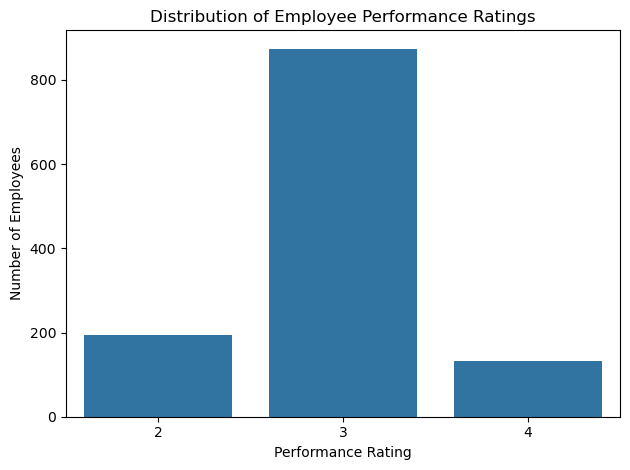

Performance Rating Counts:
PerformanceRating
2    194
3    874
4    132
Name: count, dtype: int64


In [43]:
rating_counts = df["PerformanceRating"].value_counts().sort_index()
sns.countplot(
    data=df,
    x="PerformanceRating", 
    order=sorted(df["PerformanceRating"].unique())
)

plt.title("Distribution of Employee Performance Ratings")
plt.xlabel("Performance Rating")
plt.ylabel("Number of Employees")
plt.tight_layout()
plt.show()

print("Performance Rating Counts:") 
print(rating_counts)

#### Findings and Interpretation

Performance rating 3 was the most common category, with 874 employees. A total of 194 employees received rating 2, while 132 employees received rating 4.

This shows that most employees fall into rating category 3. The differences in category sizes should be considered when training and evaluating the classification model.

### 2. Department-wise Performance Analysis

Compare employee performance ratings across departments to understand how performance varies between teams.

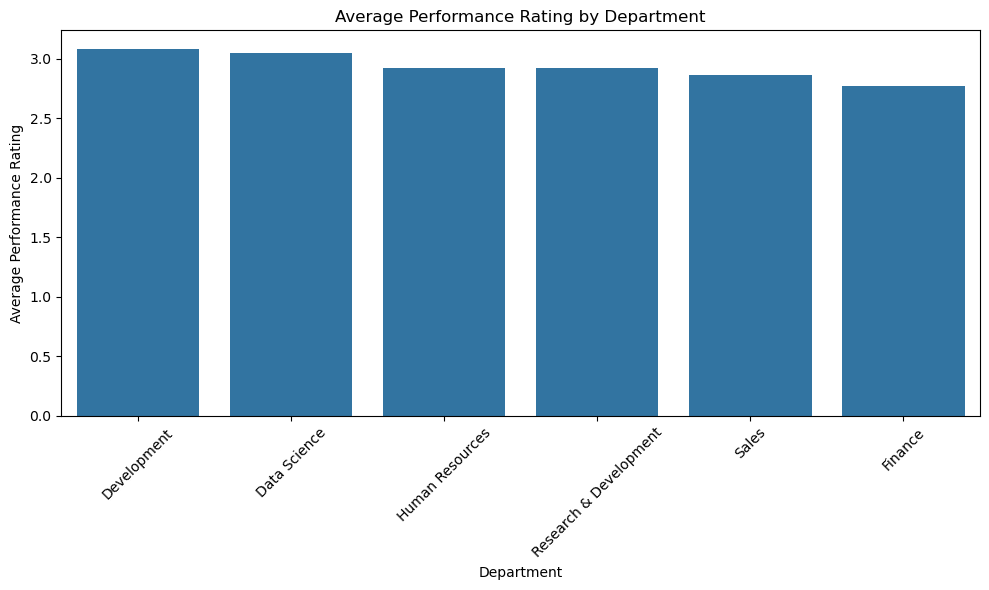

Department-Wise Performance Summary:


,count,mean,median
EmpDepartment,,,
Development,361,3.09,3.0
Data Science,20,3.05,3.0
Human Resources,54,2.93,3.0
Research & Development,343,2.92,3.0
Sales,373,2.86,3.0
Finance,49,2.78,3.0


In [44]:
department_performance = df.groupby("EmpDepartment")["PerformanceRating"].agg(["count", "mean", "median"]).sort_values(by= "mean", ascending=False)

print("Department-Wise Performance Summary:")
display(department_performance.round(2))

plt.figure(figsize=(10,6))
sns.barplot(
    data= department_performance, 
    x='EmpDepartment', 
    y='mean'
)
plt.title("Average Performance Rating by Department")
plt.xlabel("Department")
plt.ylabel("Average Performance Rating")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

#### Findings and Interpretation

The analysis shows that Development has the highest average performance rating of 3.09, followed by Data Science at 3.05. Finance has the lowest average rating of 2.78, while Sales has an average rating of 2.86.

Human Resources and Research & Development have similar average ratings of 2.93 and 2.92, respectively. The median performance rating is 3 across all departments.

Overall, the differences in average performance ratings between departments are relatively small. Development shows slightly higher average performance, while Finance and Sales have lower averages. However, the Data Science department has only 20 employees, so its result should be interpreted carefully.

These results help us compare performance across departments, but further analysis is needed to understand which factors may be related to employee performance.

### 3. Performance Rating Distribution by Department

Examine the distribution of performance ratings across departments to understand how employee performance levels differ between teams.

Performance Rating Distribution by Department:


PerformanceRating,2,3,4
EmpDepartment,,,
Data Science,5.0,85.0,10.0
Development,3.6,84.2,12.2
Finance,30.6,61.2,8.2
Human Resources,18.5,70.4,11.1
Research & Development,19.8,68.2,12.0
Sales,23.3,67.3,9.4


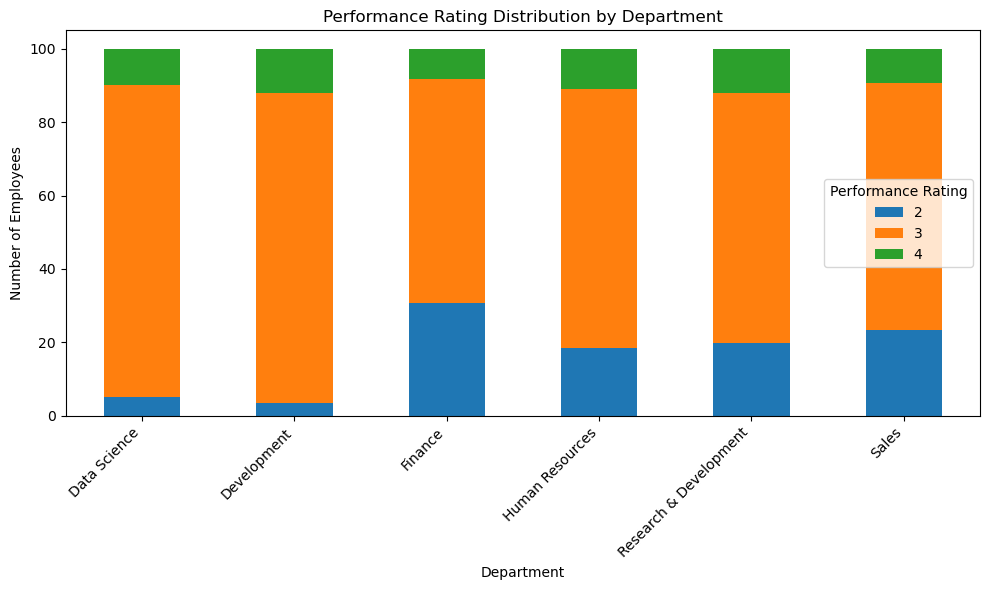

In [122]:
department_rating = pd.crosstab(
    df["EmpDepartment"], 
    df["PerformanceRating"],
    normalize = "index"
) * 100
print("Performance Rating Distribution by Department:")
display(department_rating.round(1)) 

department_rating.plot(
    kind="bar",
    stacked=True, 
    figsize = (10, 6)
)

plt.title("Performance Rating Distribution by Department")
plt.xlabel("Department")
plt.ylabel("Number of Employees")
plt.legend(title="Performance Rating")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()

#### Findings and Interpretation

Performance rating 3 is the most common rating in every department, but the share of low and high ratings differs.

Finance has the highest share of employees rated 2 (30.6%), followed by Sales (23.3%) and Research & Development (19.8%). Development has the lowest share rated 2 (3.6%) and the highest share rated 4 (12.2%), along with Research & Development (12.0%).

Data Science shows only 5% rated 2, but it has just 20 employees, so this result should be interpreted carefully.

These percentages make departments of different sizes easier to compare. They support the earlier average ratings: Finance and Sales have more low performers, while Development has fewer.

## 3: Employee Satisfaction and Work Factors

### 1. Work Environment Satisfaction vs Performance Rating

This analysis examines the relationship between employee work environment satisfaction and performance ratings. It compares average performance ratings across different satisfaction levels to identify any patterns in employee performance.

Work Environment Satisfaction vs Performance Rating:


PerformanceRating             
                                       count  mean median
EmpEnvironmentSatisfaction                               
1                                        230  2.67    3.0
2                                        242  2.65    3.0
3                                        367  3.14    3.0
4                                        361  3.13    3.0

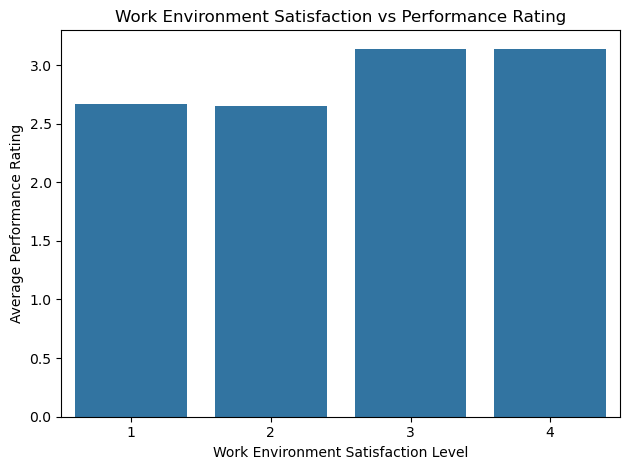

In [56]:
environment_performance = df.groupby(by="EmpEnvironmentSatisfaction").agg({"PerformanceRating":["count", "mean", "median"]})

print("Work Environment Satisfaction vs Performance Rating:")
display(environment_performance.round(2))

sns.barplot(
    data= df, 
    x="EmpEnvironmentSatisfaction", 
    y="PerformanceRating", 
    errorbar=None
)
plt.title("Work Environment Satisfaction vs Performance Rating")
plt.xlabel("Work Environment Satisfaction Level")
plt.ylabel("Average Performance Rating")
plt.tight_layout()
plt.show()

#### Findings and Interpretation

The analysis shows a difference in average performance ratings across work environment satisfaction levels. Employees with satisfaction level 1 had an average performance rating of 2.67, while those at level 2 had a slightly lower average of 2.65.

Employees with satisfaction level 3 had a higher average performance rating of 3.14, followed closely by level 4 at 3.13. This shows that employees with satisfaction levels of 3 and 4 had higher average performance ratings than those with levels of 1 and 2.

Overall, the results suggest an association between work environment satisfaction and employee performance ratings. However, this analysis alone cannot confirm that higher satisfaction causes better performance.

### 2. Job Satisfaction vs Performance Rating

This analysis examines the relationship between employee job satisfaction and performance ratings. It compares average performance ratings across different job satisfaction levels to identify patterns in employee performance.

Job Satisfaction vs Performance Rating:


PerformanceRating             
                               count  mean median
EmpJobSatisfaction                               
1                                231  2.97    3.0
2                                237  2.95    3.0
3                                354  2.90    3.0
4                                378  2.98    3.0

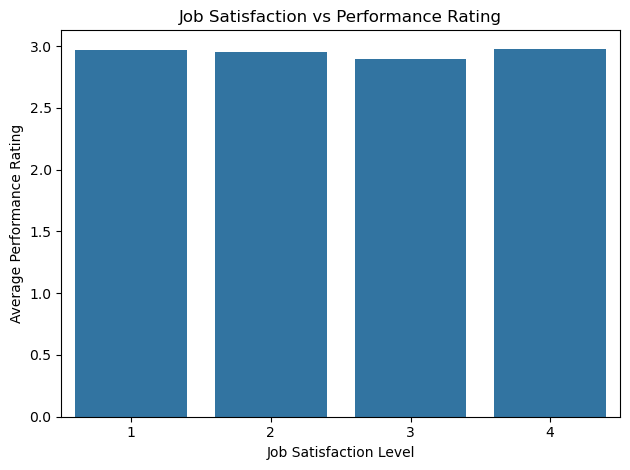

In [64]:
job_satisfaction_performance = df.groupby(by="EmpJobSatisfaction").agg({"PerformanceRating":["count", "mean", "median"]})

print("Job Satisfaction vs Performance Rating:")
display(job_satisfaction_performance.round(2))

sns.barplot(
    data=df,
    x="EmpJobSatisfaction", 
    y="PerformanceRating", 
    errorbar=None
)
plt.title("Job Satisfaction vs Performance Rating")
plt.xlabel("Job Satisfaction Level")
plt.ylabel("Average Performance Rating")
plt.tight_layout()
plt.show()

#### Findings and Interpretation

The results show that average performance ratings are quite similar across all four job satisfaction levels. Employees with satisfaction level 4 have the highest average performance rating of 2.98, closely followed by level 1 at 2.97. Level 2 has an average rating of 2.95, while level 3 has the lowest average at 2.90.

The differences between these averages are small, and the median performance rating is 3 for every satisfaction level. This suggests that job satisfaction alone does not show a strong relationship with employee performance in this analysis.

Other factors may also be associated with performance ratings, so we will examine additional employee-related factors in the following analyses.

### 3. Work-Life Balance vs Performance Rating

This analysis examines employee work-life balance levels and their relationship with performance ratings. It compares average performance ratings across the different work-life balance levels to identify any noticeable patterns.

Work Life Balance vs Performance Rating:


PerformanceRating             
                               count  mean median
EmpWorkLifeBalance                               
1                                 64  2.75    3.0
2                                294  2.92    3.0
3                                727  2.95    3.0
4                                115  3.12    3.0

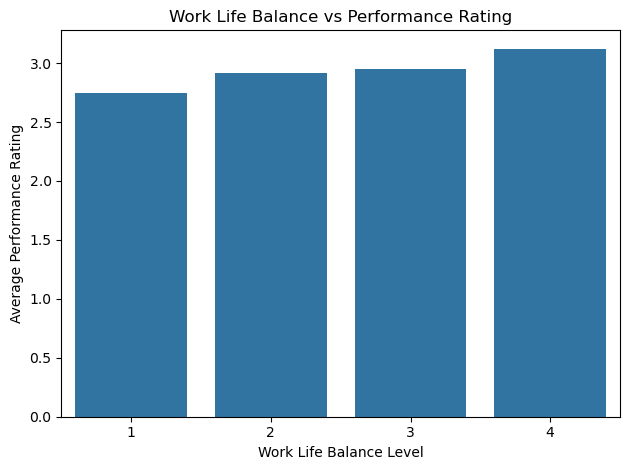

In [66]:
worklife_performance = df.groupby(by="EmpWorkLifeBalance").agg({"PerformanceRating":["count", "mean", "median"]})

print("Work Life Balance vs Performance Rating:")
display(worklife_performance.round(2))

sns.barplot(
    data= df,
    x="EmpWorkLifeBalance", 
    y="PerformanceRating", 
    errorbar=None
)
plt.title("Work Life Balance vs Performance Rating")
plt.xlabel("Work Life Balance Level")
plt.ylabel("Average Performance Rating")
plt.tight_layout()
plt.show()

#### Findings and Interpretation

The results show that employees with work-life balance level 4 have the highest average performance rating of 3.12. Employees at level 3 have an average rating of 2.95, followed by level 2 at 2.92. Level 1 has the lowest average rating of 2.75.

The results show a gradual increase in average performance ratings as work-life balance levels increase. However, the number of employees differs across the groups. For example, 727 employees are at level 3, compared with only 64 at level 1.

Overall, work-life balance may be associated with employee performance, but this analysis alone cannot confirm that better work-life balance leads to higher performance.

### 4. Job Involvement vs Performance Rating

This analysis examines whether employee job involvement levels are associated with differences in performance ratings. It compares average performance ratings across the different job involvement levels to identify any noticeable patterns.

Job Involvement vs Performance Rating:


PerformanceRating             
                              count  mean median
EmpJobInvolvement                               
1                                70  2.96    3.0
2                               294  2.96    3.0
3                               724  2.94    3.0
4                               112  2.95    3.0

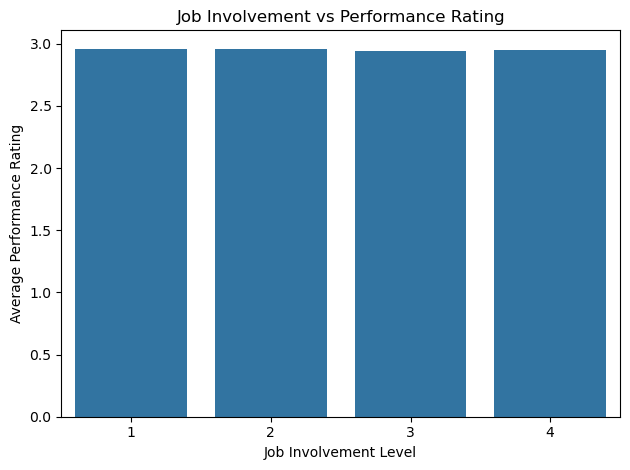

In [69]:
job_involvement_performance = df.groupby(by="EmpJobInvolvement").agg({"PerformanceRating":["count","mean", "median"]})
print("Job Involvement vs Performance Rating:")
display(job_involvement_performance.round(2))

sns.barplot(
    data=df,
    x="EmpJobInvolvement", 
    y="PerformanceRating",
    errorbar=None
)
plt.title("Job Involvement vs Performance Rating")
plt.xlabel("Job Involvement Level")
plt.ylabel("Average Performance Rating")
plt.tight_layout()
plt.show()

#### Findings and Interpretation

The analysis shows that average performance ratings are very similar across all four job involvement levels. Employees at levels 1 and 2 have an average performance rating of 2.96, while level 3 has an average of 2.94 and level 4 has an average of 2.95.

Most employees fall under job involvement level 3, with 724 employees in this group. In comparison, only 70 employees are at level 1.

Overall, there is very little difference in average performance ratings across the job involvement levels. Based on this analysis, job involvement alone does not appear to have a strong relationship with performance ratings.

### 5. Relationship Satisfaction vs Performance Rating

This analysis examines the relationship between employee relationship satisfaction and performance ratings. It compares average performance ratings across the different satisfaction levels to identify any noticeable patterns.

Relationship Satisfaction vs Performance Rating:


PerformanceRating             
                                        count  mean median
EmpRelationshipSatisfaction                               
1                                         219  2.95    3.0
2                                         247  2.96    3.0
3                                         379  2.97    3.0
4                                         355  2.92    3.0

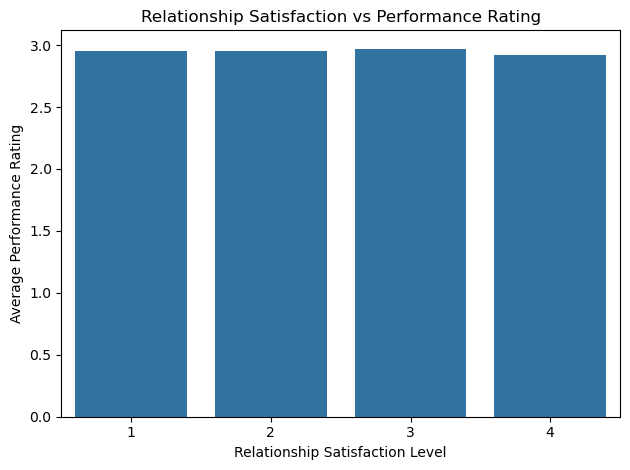

In [71]:
relationship_performance = df.groupby(by="EmpRelationshipSatisfaction").agg({"PerformanceRating":["count", "mean", "median"]})
print("Relationship Satisfaction vs Performance Rating:")
display(relationship_performance.round(2))

sns.barplot(
    data=df, 
    x="EmpRelationshipSatisfaction", 
    y="PerformanceRating", 
    errorbar=None
)
plt.title("Relationship Satisfaction vs Performance Rating")
plt.xlabel("Relationship Satisfaction Level")
plt.ylabel("Average Performance Rating")
plt.tight_layout()
plt.show()

#### Findings and Interpretation

The analysis shows that average performance ratings are very similar across all four relationship satisfaction levels. Employees at level 3 have the highest average performance rating of 2.97, followed by level 2 at 2.96 and level 1 at 2.95. Level 4 has the lowest average rating of 2.92.

The number of employees is also fairly distributed across the four levels, ranging from 219 employees at level 1 to 379 at level 3. The median performance rating is 3 for every group.

Overall, there is very little difference in average performance ratings across relationship satisfaction levels. Based on this analysis, relationship satisfaction alone does not appear to have a strong association with employee performance ratings.

## 4: Compensation, Training, and Work Experience

### 1. Salary Hike vs Performance Rating

This analysis examines salary hike percentages across employee performance rating categories. It compares the average salary hike and the distribution of salary hikes to identify differences between employees with different performance ratings.

Salary Hike vs Performance Rating:


EmpLastSalaryHikePercent              
                                     count   mean median
PerformanceRating                                       
2                                      194  15.07   14.0
3                                      874  14.43   14.0
4                                      132  20.70   21.0

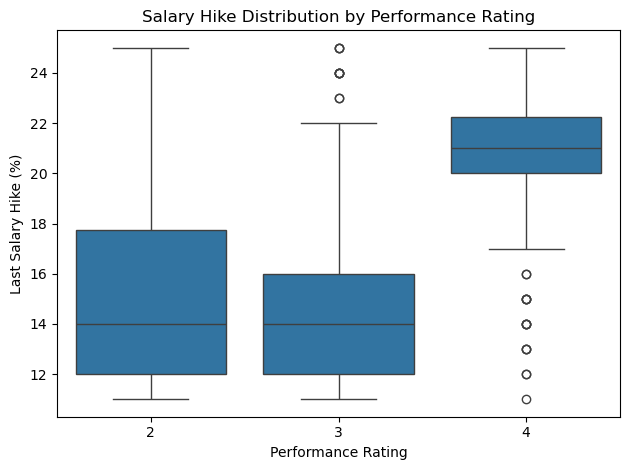

In [77]:
salary_hike_performance = df.groupby(by="PerformanceRating").agg({"EmpLastSalaryHikePercent":["count", "mean", "median"]})
print("Salary Hike vs Performance Rating:")
display(salary_hike_performance.round(2))

sns.boxplot(
    data= df, 
    x="PerformanceRating", 
    y="EmpLastSalaryHikePercent"
)
plt.title("Salary Hike Distribution by Performance Rating")
plt.xlabel("Performance Rating")
plt.ylabel("Last Salary Hike (%)")
plt.tight_layout()
plt.show()

#### Findings and Interpretation

The analysis shows that employees with a performance rating of 4 received a higher average salary hike of 20.70%, compared with 15.07% for employees rated 2 and 14.43% for employees rated 3. The median salary hike was 21% for rating 4 and 14% for both ratings 2 and 3.

The boxplot also shows that salary hike percentages vary within each performance rating group, with some potential outliers.

Overall, employees with a performance rating of 4 received higher salary hikes on average than employees in the other two groups. This suggests an association between salary hike percentage and performance rating in the dataset. However, it does not mean that higher salary hikes lead to better performance, as salary hikes may also reflect previous performance evaluations.

### 2. Training Frequency vs Performance Rating

This analysis examines whether the number of training sessions attended by employees last year is associated with differences in their performance ratings. It compares average performance ratings across training frequency groups to identify any noticeable patterns.

Training Frequency vs Performance Rating:


PerformanceRating             
                                  count  mean median
TrainingTimesLastYear                               
0                                    44  2.86    3.0
1                                    56  2.95    3.0
2                                   445  2.95    3.0
3                                   413  2.98    3.0
4                                    98  2.92    3.0
5                                    98  2.94    3.0
6                                    46  2.87    3.0

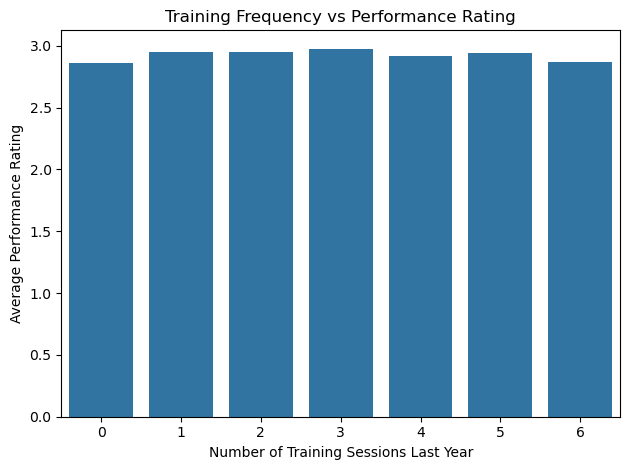

In [81]:
training_performance = df.groupby(by="TrainingTimesLastYear").agg({"PerformanceRating":["count", "mean", "median"]})
print("Training Frequency vs Performance Rating:")
display(training_performance.round(2))

sns.barplot(
    data= df,
    x="TrainingTimesLastYear",
    y="PerformanceRating", 
    errorbar=None
)
plt.title("Training Frequency vs Performance Rating")
plt.xlabel("Number of Training Sessions Last Year")
plt.ylabel("Average Performance Rating")
plt.tight_layout()
plt.show()

#### Findings and Interpretation

The analysis shows that employees who attended 3 training sessions last year had the highest average performance rating of 2.98. Employees who attended 1 or 2 sessions had an average rating of 2.95, while those who attended 4 or 5 sessions had average ratings of 2.92 and 2.94, respectively.

Employees who did not attend any training sessions had an average rating of 2.86, while those who attended 6 sessions had an average rating of 2.87. The median performance rating was 3 across all training frequency groups.

Overall, the average performance ratings show only small differences across the groups. The results do not indicate a clear pattern in which attending more training sessions is consistently associated with higher performance ratings. However, this analysis alone cannot determine whether training affects employee performance.

### 3. Overtime vs Performance Rating

This analysis compares employee performance ratings between employees who work overtime and those who do not. It examines average performance ratings and employee counts to identify any differences between the two groups.

Overtime vs Performance Rating:


PerformanceRating             
                     count  mean median
OverTime                               
No                     847  2.93    3.0
Yes                    353  2.99    3.0

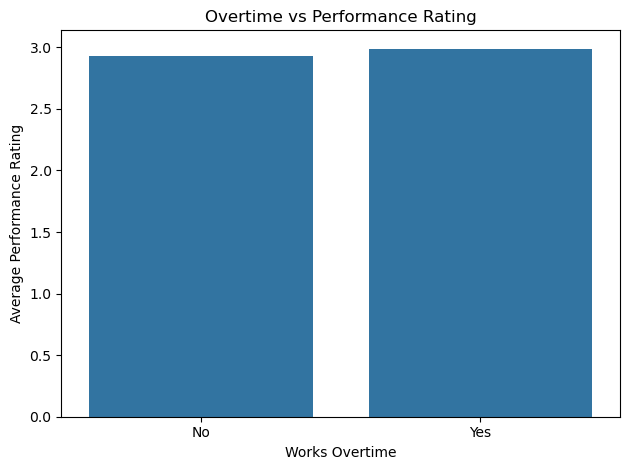

In [119]:
overtime_performance = df.groupby(by="OverTime").agg({"PerformanceRating":["count", "mean", "median"]})
print("Overtime vs Performance Rating:")
display(overtime_performance.round(2))

sns.barplot(
    data=df,
    x="OverTime",
    y="PerformanceRating", 
    errorbar=None
)
plt.title("Overtime vs Performance Rating")
plt.xlabel("Works Overtime")
plt.ylabel("Average Performance Rating")
plt.tight_layout()
plt.show()

#### Findings and Interpretation

The analysis shows that employees who work overtime have an average performance rating of 2.99, while employees who do not work overtime have an average rating of 2.93. The dataset contains 353 employees who work overtime and 847 employees who do not.

The median performance rating is 3 for both groups. Although employees who work overtime have a slightly higher average rating, the difference is small.

Overall, the results show a slight association between overtime and performance ratings. However, this does not mean that working overtime improves employee performance. Other factors may also influence performance ratings.

### 4. Work Experience vs Performance Rating

This analysis examines the relationship between employee work experience and performance ratings. It compares total working years, years spent at the company, and years in the current role across performance rating groups to identify any noticeable patterns.


TotalWorkExperienceInYears vs Performance Rating:


TotalWorkExperienceInYears              
                                       count   mean median
PerformanceRating                                         
2                                        194  12.75   10.0
3                                        874  11.08    9.0
4                                        132  10.92    9.0


ExperienceYearsAtThisCompany vs Performance Rating:


ExperienceYearsAtThisCompany             
                                         count  mean median
PerformanceRating                                          
2                                          194  9.10    8.0
3                                          874  6.68    5.0
4                                          132  6.77    5.0


ExperienceYearsInCurrentRole vs Performance Rating:


ExperienceYearsInCurrentRole             
                                         count  mean median
PerformanceRating                                          
2                                          194  5.79    5.5
3                                          874  4.01    3.0
4                                          132  3.98    3.0

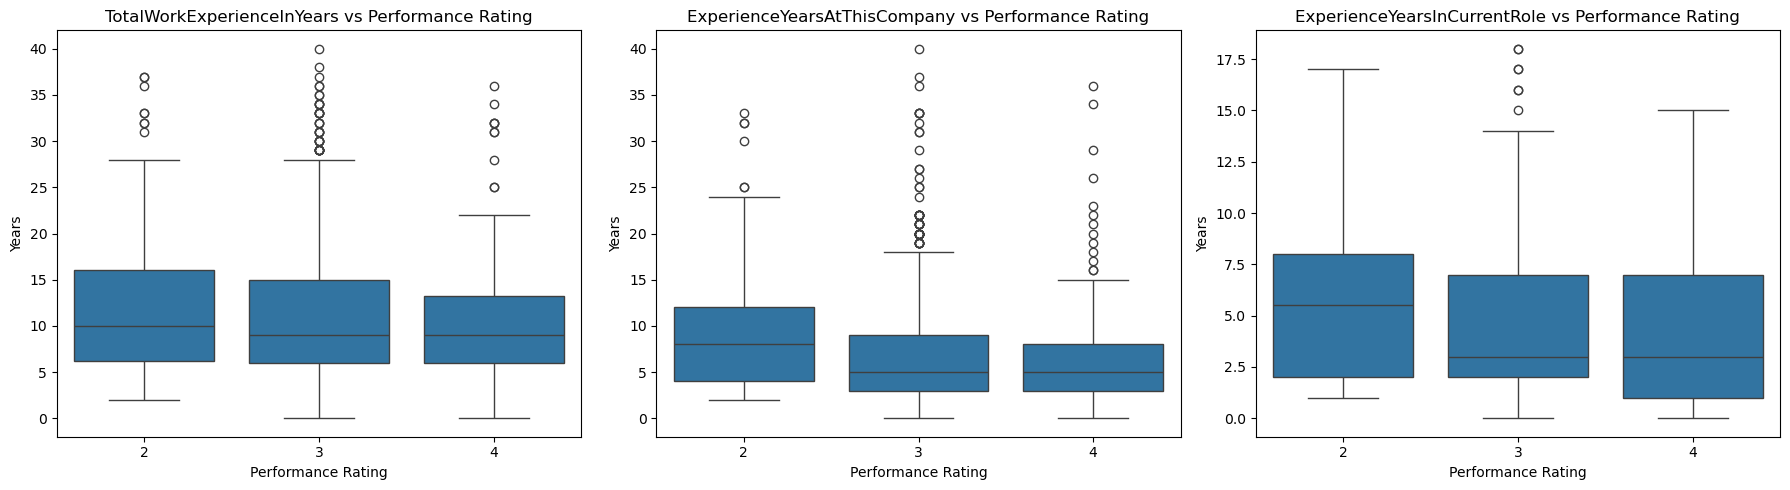

In [94]:
experience_columns = [
    "TotalWorkExperienceInYears", 
    "ExperienceYearsAtThisCompany", 
    "ExperienceYearsInCurrentRole"
]

for columns in experience_columns: 
    print(f"\n{columns} vs Performance Rating:")

    experience_performance = df.groupby(by="PerformanceRating").agg({f"{columns}":["count", "mean", "median"]})
    display(experience_performance.round(2))

fig, axes = plt.subplots(1, 3, figsize=(18, 5))
for ax, columns in zip(axes, experience_columns): 
    sns.boxplot(
        data=df,
        x="PerformanceRating", 
        y=columns, 
        ax=ax
    )

    ax.set_title(f"{columns} vs Performance Rating")
    ax.set_xlabel("Performance Rating")
    ax.set_ylabel("Years")

plt.tight_layout()
plt.show()

#### Findings and Interpretation

The analysis shows differences in work experience across the three performance rating groups.

Employees with a performance rating of 2 had the highest average total work experience of 12.75 years, followed by employees rated 3 at 11.08 years and employees rated 4 at 10.92 years. The median total work experience was 10 years for rating 2 and 9 years for ratings 3 and 4.

A similar pattern appears in experience at the company. Employees rated 2 had an average of 9.10 years at the company, compared with 6.68 years for rating 3 and 6.77 years for rating 4. Their median experience was 8 years for rating 2 and 5 years for ratings 3 and 4.

For experience in the current role, employees rated 2 had an average of 5.79 years, while employees rated 3 and 4 had averages of 4.01 and 3.98 years, respectively. The median was 5.5 years for rating 2 and 3 years for ratings 3 and 4.

The boxplots also show several potential outliers, particularly among employees with longer work experience. These values represent employees whose experience differs from the typical range and should not automatically be removed.

Overall, employees with a performance rating of 2 had more work experience on average than employees rated 3 or 4. However, the differences between ratings 3 and 4 were small. This suggests that work experience alone may not explain employee performance ratings. Other factors should also be considered when building the prediction model.

## 5: Categorical Feature Analysis

### 1. Job Role vs Performance Rating

This analysis compares average performance ratings across different job roles and examines the number of employees in each role. It helps identify differences in average ratings while considering the size of each job role group.

Job Role vs Performance Rating:


PerformanceRating             
                                      count  mean median
EmpJobRole                                              
Business Analyst                         16  3.19    3.0
Developer                               236  3.11    3.0
Technical Lead                           38  3.08    3.0
Data Scientist                           20  3.05    3.0
Delivery Manager                         12  3.00    3.0
Senior Developer                         52  3.00    3.0
Technical Architect                       7  3.00    3.0
Manufacturing Director                   33  2.97    3.0
Research Scientist                       77  2.96    3.0
Manager                                  51  2.96    3.0
Manager R&D                              94  2.94    3.0
Human Resources                          45  2.91    3.0
Research Director                        19  2.89    3.0
Sales Representative                     69  2.87    3.0
Laboratory Technician                    64  2.86    3.0
Sales Executive                         270  2.86    3.0
Healthcare Representative                33  2.85    3.0
Senior Manager R&D                       15  2.80    3.0
Finance Manager                          49  2.78    3.0

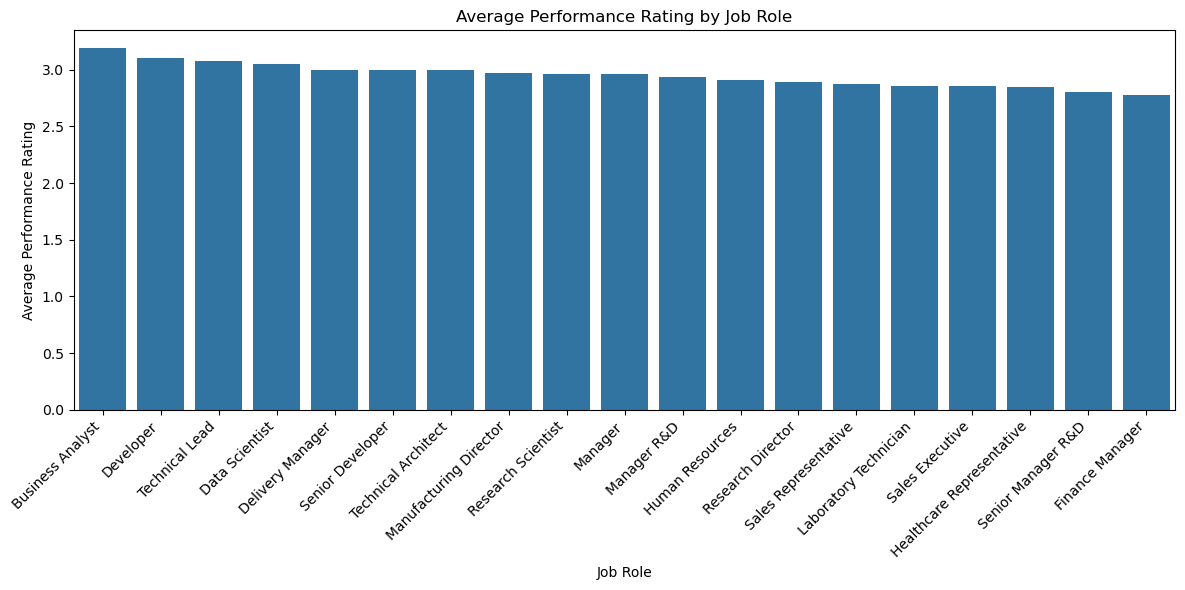

In [107]:
jobrole_performance = df.groupby(by="EmpJobRole").agg({"PerformanceRating":["count", "mean", "median"]}).sort_values(by=("PerformanceRating","mean"), ascending=False)
print("Job Role vs Performance Rating:")
display(jobrole_performance.round(2))

plt.figure(figsize=(12,6))
sns.barplot(
    data=df,
    x="EmpJobRole", 
    y="PerformanceRating",
    errorbar=None,
    order=jobrole_performance.index
)
plt.title("Average Performance Rating by Job Role")
plt.xlabel("Job Role")
plt.ylabel("Average Performance Rating")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()

#### Findings and Interpretation

The analysis shows differences in average performance ratings across job roles. Business Analysts have the highest average performance rating of 3.19, followed by Developers at 3.11 and Technical Leads at 3.08. Data Scientists have an average rating of 3.05.

On the other hand, Finance Managers have the lowest average performance rating of 2.78, followed by Senior Managers R&D at 2.80 and Healthcare Representatives at 2.85. Sales Executives and Laboratory Technicians both have an average rating of 2.86.

Developers have 236 employees, while Sales Executives have the largest group, with 270 employees. In comparison, some roles have much smaller groups, such as Technical Architects with 7 employees and Delivery Managers with 12 employees. The average ratings for these smaller groups should therefore be interpreted carefully.

The median performance rating is 3 for every job role, indicating that the middle rating is the same across all groups, despite differences in their average ratings.

Overall, Business Analysts and Developers show relatively higher average performance ratings, while Finance Managers and Senior Managers R&D show lower averages. These differences suggest that performance ratings vary by job role, but job role alone may not explain employee performance. Other employee and workplace factors should also be considered.

### 2. Business Travel Frequency vs Performance Rating

This analysis compares employee performance ratings across different business travel frequencies. It examines the average performance rating and employee count for each group to identify whether performance ratings differ between employees who travel frequently, travel occasionally, or do not travel.

PerformanceRating             
                                    count  mean median
BusinessTravelFrequency                               
Non-Travel                            132  2.98    3.0
Travel_Frequently                     222  2.97    3.0
Travel_Rarely                         846  2.94    3.0

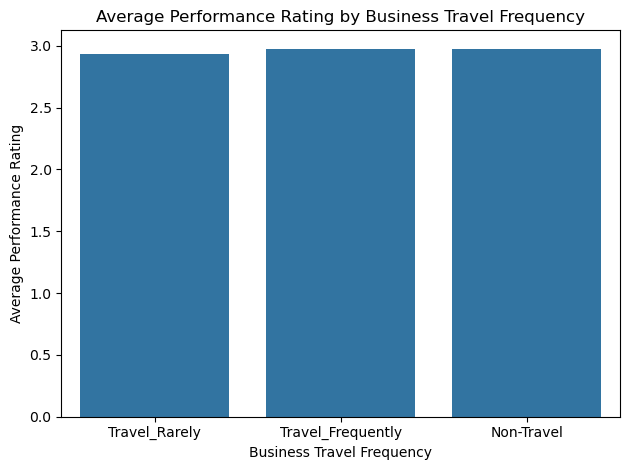

In [120]:
travel_performance = df.groupby("BusinessTravelFrequency").agg({"PerformanceRating":["count", "mean", "median"]}).sort_values(by=("PerformanceRating","mean"), ascending=False)
display(travel_performance.round(2))

sns.barplot(
    data=df,
    x="BusinessTravelFrequency", 
    y="PerformanceRating", 
    errorbar=None
)
plt.title("Average Performance Rating by Business Travel Frequency")
plt.xlabel("Business Travel Frequency")
plt.ylabel("Average Performance Rating")
plt.tight_layout()
plt.show()

#### Findings and Interpretation

The analysis shows that employees who do not travel for business have the highest average performance rating of 2.98. Employees who travel frequently have an average rating of 2.97, while employees who travel rarely have an average rating of 2.94.

Most employees belong to the Travel_Rarely group, with 846 employees. The Travel_Frequently group contains 222 employees, while 132 employees belong to the Non-Travel group. The median performance rating is 3 for all three groups.

Overall, the average performance ratings are very similar across business travel groups. The results do not show a substantial difference in performance based on business travel frequency. However, these findings describe an association and do not establish that business travel frequency causes changes in employee performance.

### 3. Additional Employee Characteristics

This analysis examines selected employee characteristics, including education level, age, gender, and attrition, to identify any noticeable differences in performance ratings. These analyses provide additional context for understanding the employee dataset and may help identify features worth considering during model development.

In [113]:
education_performance = df.groupby("EmpEducationLevel").agg({"PerformanceRating":["count","mean","median"]})
age_performance = df.groupby("PerformanceRating").agg({"Age":["count", "mean", "median"]})
gender_performance = df.groupby("Gender").agg({"PerformanceRating":["count", "mean", "median"]})
attrition_performance = df.groupby("Attrition").agg({"PerformanceRating":["count", "mean", "median"]})

print("Education Level vs Performance Rating:")
display(education_performance.round(2))
print("Age vs Performance Rating:")
display(age_performance.round(2))
print("Gender vs Performance Rating:")
display(gender_performance.round(2))
print("Attrition vs Performance Rating:")
display(attrition_performance.round(2))

Education Level vs Performance Rating:


PerformanceRating             
                              count  mean median
EmpEducationLevel                               
1                               148  2.87    3.0
2                               239  2.95    3.0
3                               449  2.99    3.0
4                               322  2.94    3.0
5                                42  2.88    3.0

Age vs Performance Rating:


Age              
                  count   mean median
PerformanceRating                    
2                   194  37.80   36.0
3                   874  36.78   35.0
4                   132  36.50   36.0

Gender vs Performance Rating:


PerformanceRating             
                   count  mean median
Gender                               
Female               475  2.95    3.0
Male                 725  2.95    3.0

Attrition vs Performance Rating:


PerformanceRating             
                      count  mean median
Attrition                               
No                     1022  2.96    3.0
Yes                     178  2.90    3.0

#### Findings and Interpretation

The analysis examined education level, age, gender, and attrition to understand whether these employee characteristics show differences in performance ratings.

**Education Level:** Employees with education level 3 had the highest average performance rating of 2.99, followed by level 2 at 2.95 and level 4 at 2.94. Levels 1 and 5 had average ratings of 2.87 and 2.88, respectively. The median rating was 3 across all education levels. Overall, the average ratings were similar, with no clear pattern of increasing performance as education level increased.

**Age:** Employees with a performance rating of 2 had the highest average age of 37.80 years, compared with 36.78 years for rating 3 and 36.50 years for rating 4. The differences were relatively small, suggesting that age alone does not clearly distinguish between performance rating groups.

**Gender:** Female and male employees both had an average performance rating of 2.95, with a median rating of 3 for both groups. This indicates that the average performance ratings were identical for the two gender groups in this dataset.

**Attrition:** Employees who had not left the company had an average performance rating of 2.96, while employees who had left had an average rating of 2.90. The median rating was 3 for both groups. Although the difference is small, it may be useful to examine attrition alongside other employee characteristics during further analysis.

Overall, these characteristics show limited differences in average performance ratings. Education level, age, gender, and attrition should be evaluated alongside other features rather than used individually to explain employee performance. These findings describe patterns in this dataset and do not establish cause-and-effect relationships.

## 6: Correlation Analysis

### 1. Correlation with Performance Rating

This analysis calculates the correlation between numerical features and employee performance ratings. A horizontal bar chart will display the correlations in order of strength, helping identify numerical features with stronger positive or negative linear relationships with performance ratings.

Correlation indicates association rather than causation. A weak linear correlation does not necessarily mean that a feature is unimportant for machine learning.

Correlation of Numerical Features with Performance Rating:


,Correlation
EmpEnvironmentSatisfaction,0.396
EmpLastSalaryHikePercent,0.334
YearsSinceLastPromotion,-0.168
ExperienceYearsInCurrentRole,-0.148
EmpWorkLifeBalance,0.124
YearsWithCurrManager,-0.122
ExperienceYearsAtThisCompany,-0.112
EmpJobLevel,-0.077
TotalWorkExperienceInYears,-0.068
DistanceFromHome,-0.046


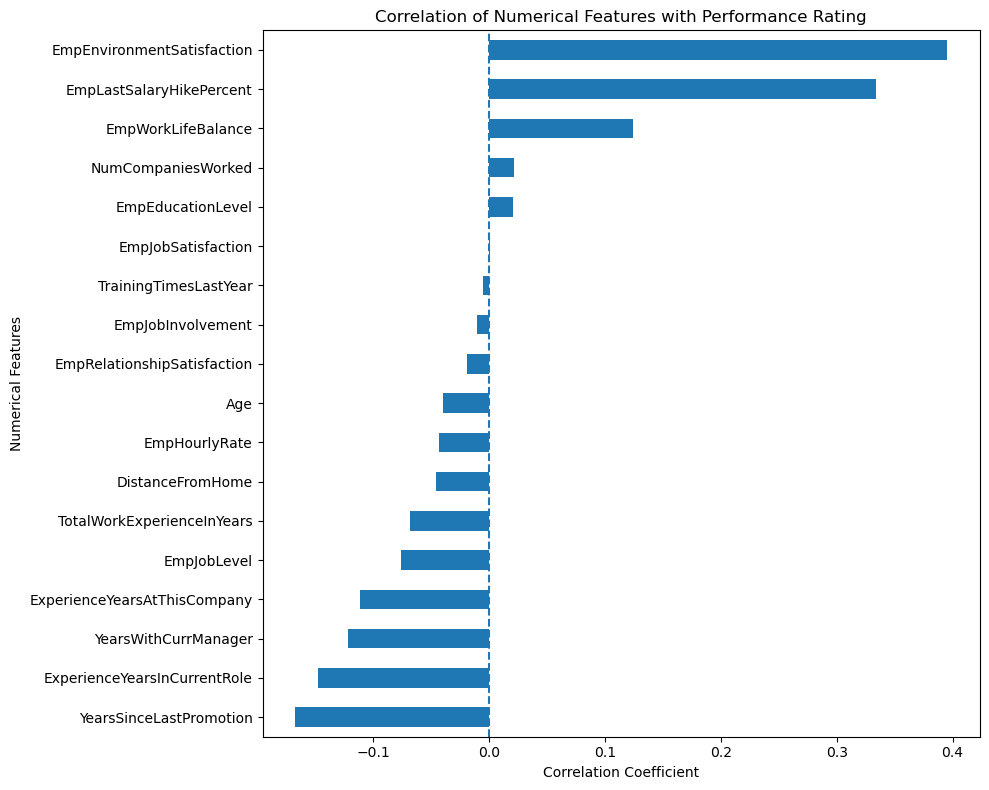

In [117]:
numeric_col = df.select_dtypes(include="number")

performance_corr = (
    numeric_col.corr()["PerformanceRating"].drop("PerformanceRating").sort_values(key=abs, ascending=False)
)
print("Correlation of Numerical Features with Performance Rating:")
display(performance_corr.to_frame(name="Correlation").round(3))

plt.figure(figsize=(10, 8))

performance_corr.sort_values().plot(kind="barh")

plt.title("Correlation of Numerical Features with Performance Rating")
plt.xlabel("Correlation Coefficient")
plt.ylabel("Numerical Features")
plt.axvline(x=0, linestyle="--")
plt.tight_layout()
plt.show()

#### Findings and Interpretation

The correlation analysis was performed to identify numerical features that have linear relationships with employee performance ratings.

**Positive Correlations:**

- Employee Environment Satisfaction has the strongest positive correlation with PerformanceRating at 0.396. This indicates that higher environment satisfaction tends to be associated with higher performance ratings.
- EmpLastSalaryHikePercent has a positive correlation of 0.334, suggesting that higher salary hike percentages are associated with higher performance ratings.
- EmpWorkLifeBalance has a positive correlation of 0.124, indicating a relatively weak positive relationship with performance ratings.

**Negative Correlations:**

- YearsSinceLastPromotion has the strongest negative correlation at -0.168.
- ExperienceYearsInCurrentRole has a correlation of -0.148.
- YearsWithCurrManager and ExperienceYearsAtThisCompany have correlations of -0.122 and -0.112, respectively.

These results indicate that higher values of these experience-related features tend to be associated with slightly lower performance ratings in this dataset. However, correlation does not explain why these patterns occur.

**Weak or Near-Zero Correlations:**

Features such as EmpJobSatisfaction (0.001), TrainingTimesLastYear (-0.005), EmpJobInvolvement (-0.011), and EmpRelationshipSatisfaction (-0.020) have correlations close to zero. This indicates that they have little or no linear relationship with performance ratings in this analysis.

Overall, Employee Environment Satisfaction and EmpLastSalaryHikePercent have the strongest linear associations with PerformanceRating among the numerical features examined. However, correlation measures only linear relationships. Features with weak correlations may still be useful to a machine learning model because they could have nonlinear relationships or interact with other features. Therefore, feature selection should consider model performance and other evaluation results rather than correlation alone.

### 2. Correlation Heatmap

This analysis uses a correlation heatmap to examine linear relationships among numerical features in the employee dataset. The heatmap helps identify strongly correlated feature pairs and potential multicollinearity. Correlation indicates association rather than causation, and a high correlation does not automatically mean that a feature should be removed.

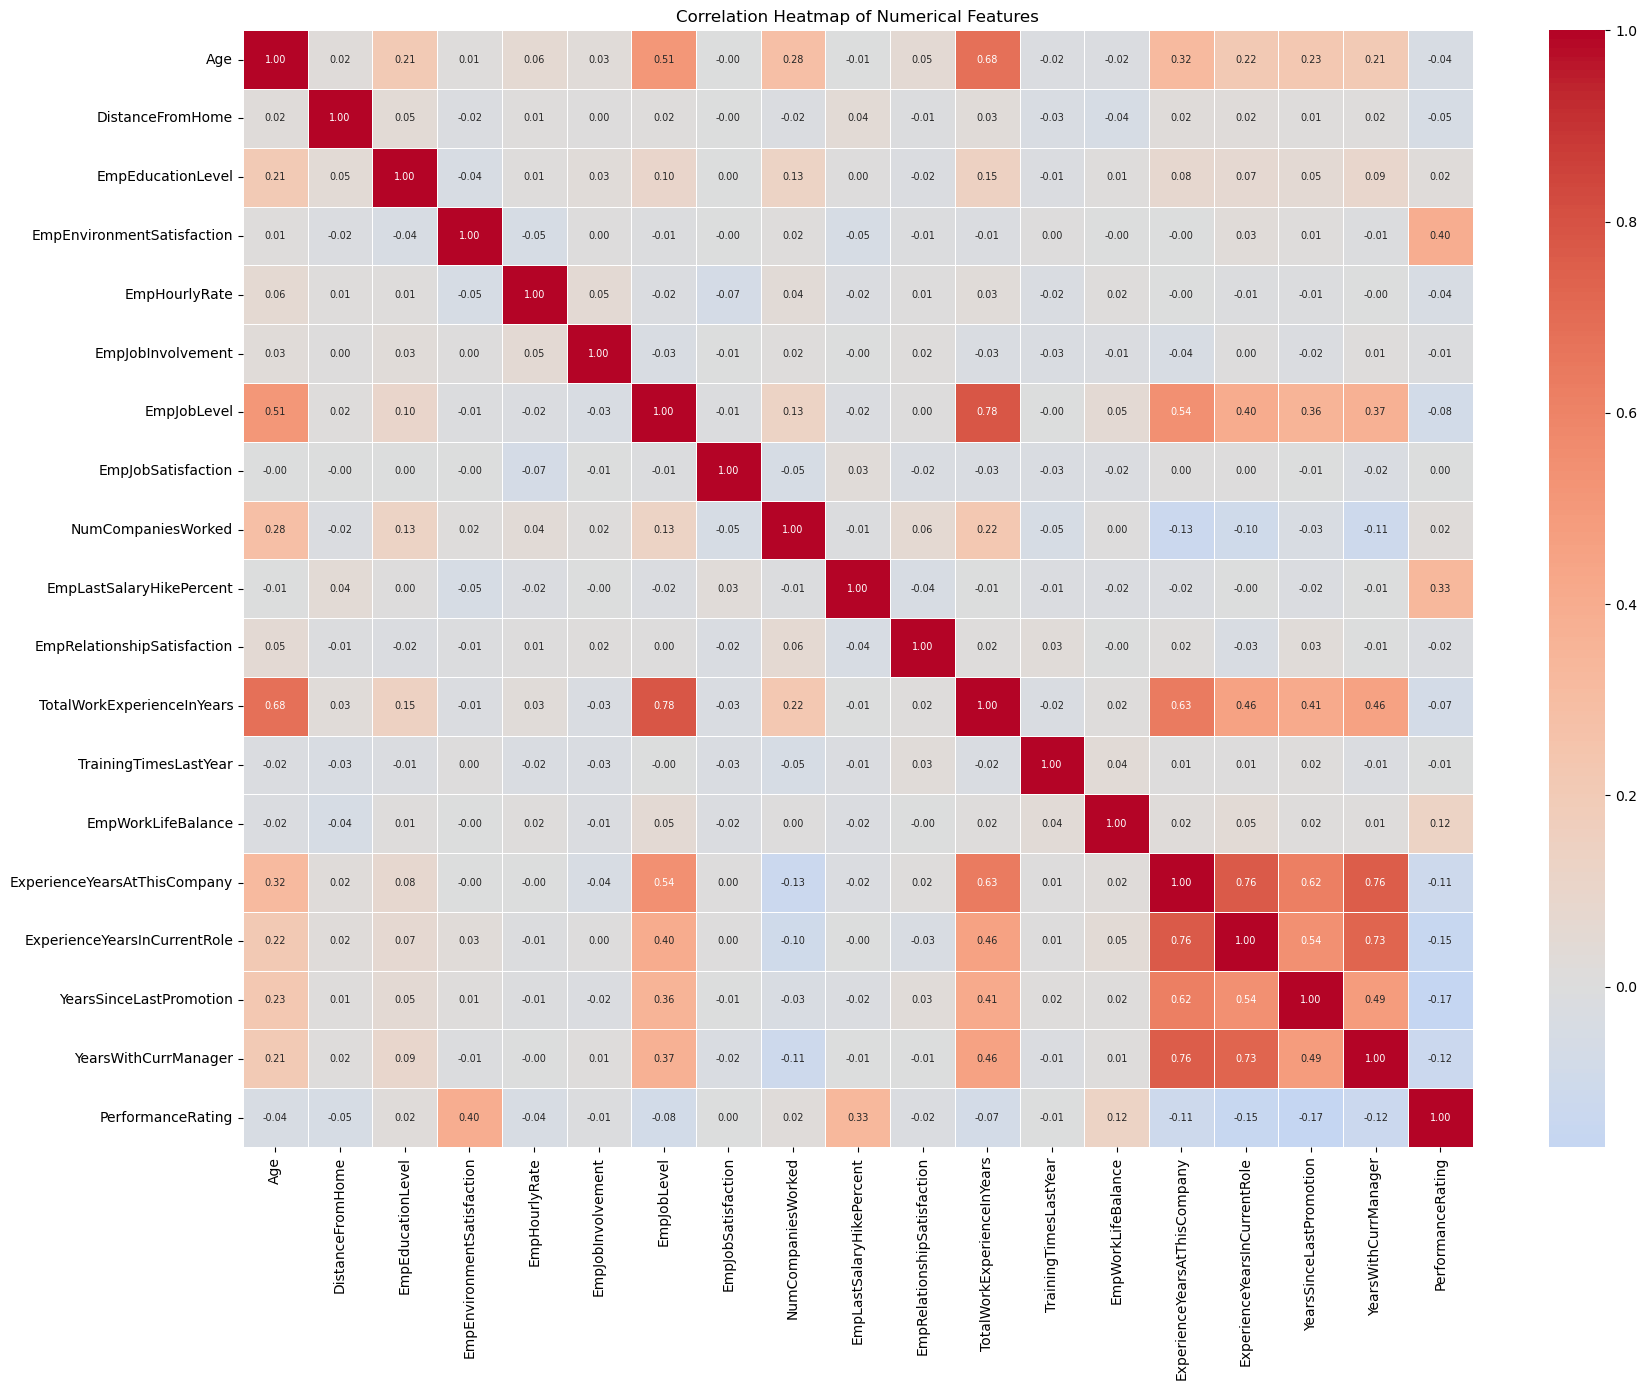

In [123]:
numeric_df = df.select_dtypes(include="number")

correlation_matrix = numeric_df.corr()

plt.figure(figsize=(18, 14))

sns.heatmap(
    correlation_matrix,
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    center=0,
    linewidths=0.5,
    annot_kws={"size": 7}
)

plt.title("Correlation Heatmap of Numerical Features")
plt.tight_layout()
plt.show()

#### Findings and Interpretation

Environment satisfaction (0.40), salary hike percentage (0.33), and years since last promotion (-0.17) show the strongest relationships with performance rating. Several experience and career-level features are strongly correlated with each other, so they carry overlapping information. Tree-based models handle this well, but linear models may need feature selection. Final feature choices will be based on model evaluation, not correlation alone.

## 7: Exploratory Data Analysis Summary

### 1. Key Findings

#### 1. Overall Performance Rating Distribution

Performance rating 3 was the most common category, with 874 employees. A total of 194 employees received rating 2, while 132 received rating 4. This shows that the dataset is imbalanced across performance rating categories, which should be considered when training and evaluating the classification model.

#### 2. Department-Wise Performance

Development had the highest average departmental performance rating at 3.09, followed by Data Science at 3.05. Finance had the lowest average at 2.78, followed by Sales at 2.86. The differences were relatively small, and the results for smaller departments should be interpreted carefully.

#### 3. Employee Satisfaction and Work Factors

Employee environment satisfaction showed a positive correlation of 0.396 with performance rating. Employees with environment satisfaction levels 3 and 4 also had higher average performance ratings than those with levels 1 and 2.

Work-life balance showed a positive correlation of 0.124. However, job satisfaction, job involvement, and relationship satisfaction showed little difference in average performance ratings across their respective groups.

#### 4. Salary Hike and Training

Salary hike percentage had a positive correlation of 0.334 with performance rating. Employees rated 4 received an average salary hike of 20.70%, compared with 15.07% for rating 2 and 14.43% for rating 3.

Training frequency showed only small differences in average performance ratings across groups. The results did not show a clear pattern in which more training sessions were consistently associated with higher performance ratings.

#### 5. Overtime and Business Travel

Employees who worked overtime had an average performance rating of 2.99, compared with 2.93 for employees who did not work overtime. Business travel groups also had similar average ratings, ranging from 2.94 to 2.98.

These differences were small and do not establish that overtime or business travel causes changes in performance.

#### 6. Work Experience

Employees with a performance rating of 2 had higher average total work experience, company experience, and current-role experience than employees rated 3 or 4. However, the differences between ratings 3 and 4 were small.

This suggests that work experience alone may not explain employee performance ratings.

#### 7. Job Role and Additional Characteristics

Business Analysts had the highest average job-role performance rating at 3.19, followed by Developers at 3.11. Finance Managers had the lowest average at 2.78. Employee counts varied substantially across job roles, so smaller groups require careful interpretation.

Gender groups had identical average performance ratings of 2.95. Education level and age showed relatively small differences in average ratings. Employees who had left the company had an average rating of 2.90, compared with 2.96 for employees who had not left.

#### 8. Important Correlations

Employee environment satisfaction (0.396) and salary hike percentage (0.334) had the strongest positive correlations with performance rating among the numerical features examined.

Years since last promotion had a negative correlation of -0.168, while experience in the current role had a correlation of -0.148.

The heatmap also identified strong correlations among experience-related features, including job level and total work experience (0.78), and company experience and current-role experience (0.76). These relationships may indicate overlapping information among features.

Overall, the EDA identified several useful patterns, but correlation and group comparisons alone cannot establish causation or determine which features will be most useful for prediction.

#### Top 3 Factors Associated with Performance

1. **Environment satisfaction** (correlation 0.40): employees with satisfaction levels 3 and 4 had average ratings of about 3.1, compared with about 2.7 for levels 1 and 2.
2. **Salary hike percentage** (correlation 0.33): employees rated 4 received an average hike of 20.7%, compared with about 14 to 15% for the others. The hike may partly reflect earlier performance ratings.
3. **Years since last promotion** (correlation -0.17): employees rated 2 waited an average of 3.7 years, compared with about 1.9 years for ratings 3 and 4.

Several experience features are also linked to lower ratings, but they overlap with the promotion finding.

### 2. EDA Conclusion

The exploratory data analysis helped identify patterns in employee performance ratings across departments, satisfaction levels, salary hikes, training frequency, overtime, work experience, job roles, and other employee characteristics.

The results showed that employee environment satisfaction and salary hike percentage had the strongest positive correlations with performance rating among the numerical features examined. Several experience-related features were strongly correlated with one another, while training frequency, job satisfaction, job involvement, and relationship satisfaction showed weak linear relationships with performance rating.

The analysis also revealed that performance rating 3 was the dominant category. This class distribution should be considered when splitting the data, training the classification models, and evaluating their performance.

These findings provide a starting point for feature selection and model development. However, features should not be selected or removed based on correlation alone. Their usefulness should be evaluated using appropriate preprocessing, classification models, and evaluation metrics.

The next stage of the project will involve preparing the features and target variable, splitting the data into training and testing sets, training classification models, and comparing their performance. Evaluation should include metrics such as precision, recall, F1-score, and a confusion matrix, alongside accuracy, to assess how well the models identify all three performance rating categories.

The final model should be selected based on its overall evaluation results and suitability for the project objectives.